 Анализ экспериментов MLflow.

Сравнение 5 моделей, обученных скриптом `src/models/train.py` с подбором гиперпараметров (GridSearchCV, 5-fold CV). Данные загружаются из MLflow (`mlflow.db`). Лучшая модель выбирается по ROC-AUC на кросс-валидации.

In [ ]:
drive.mount('/content/drive')
PROJECT_DIR = "/content/drive/MyDrive/3семестр/pd-model"
%cd {PROJECT_DIR}
!pip install -q "mlflow>=3.0"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/3семестр/pd-model


In [ ]:
from google.colab import drive
import mlflow
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

In [ ]:
# Таблица всех экспериментов из MLflow
mlflow.set_tracking_uri(f"sqlite:///{PROJECT_DIR}/mlflow.db")
runs = mlflow.search_runs(experiment_names=["pd-model-credit-default"])

board = pd.DataFrame({
    "модель": runs["tags.mlflow.runName"],
    "CV ROC-AUC": runs["metrics.cv_roc_auc"],
    "± std": runs["metrics.cv_roc_auc_std"],
    "Train ROC-AUC": runs["metrics.train_roc_auc"],
    "Test ROC-AUC": runs["metrics.test_roc_auc"],
    "Gini": runs["metrics.test_gini"],
    "Precision": runs["metrics.test_precision"],
    "Recall": runs["metrics.test_recall"],
    "F1": runs["metrics.test_f1"],
    "порог": runs["params.threshold"],
    "время, с": runs["metrics.fit_time_sec"],
}).sort_values("CV ROC-AUC", ascending=False).round(4)
board

,модель,CV ROC-AUC,± std,Train ROC-AUC,Test ROC-AUC,Gini,Precision,Recall,F1,порог,"время, с"
0,hist_gb,0.7878,0.0074,0.8199,0.7761,0.5523,0.5096,0.5596,0.5334,0.28,45.8169
2,random_forest,0.7874,0.0087,0.8319,0.7759,0.5517,0.5090,0.5739,0.5395,0.28,234.2115
1,gradient_boosting,0.7873,0.0074,0.8155,0.7766,0.5533,0.4899,0.5867,0.5340,0.25,488.6886
3,decision_tree,0.7748,0.0069,0.7972,0.7612,0.5224,0.5367,0.4910,0.5128,0.29,18.8173
4,logreg,0.7578,0.0123,0.7616,0.7509,0.5017,0.4814,0.5573,0.5166,0.24,15.0691


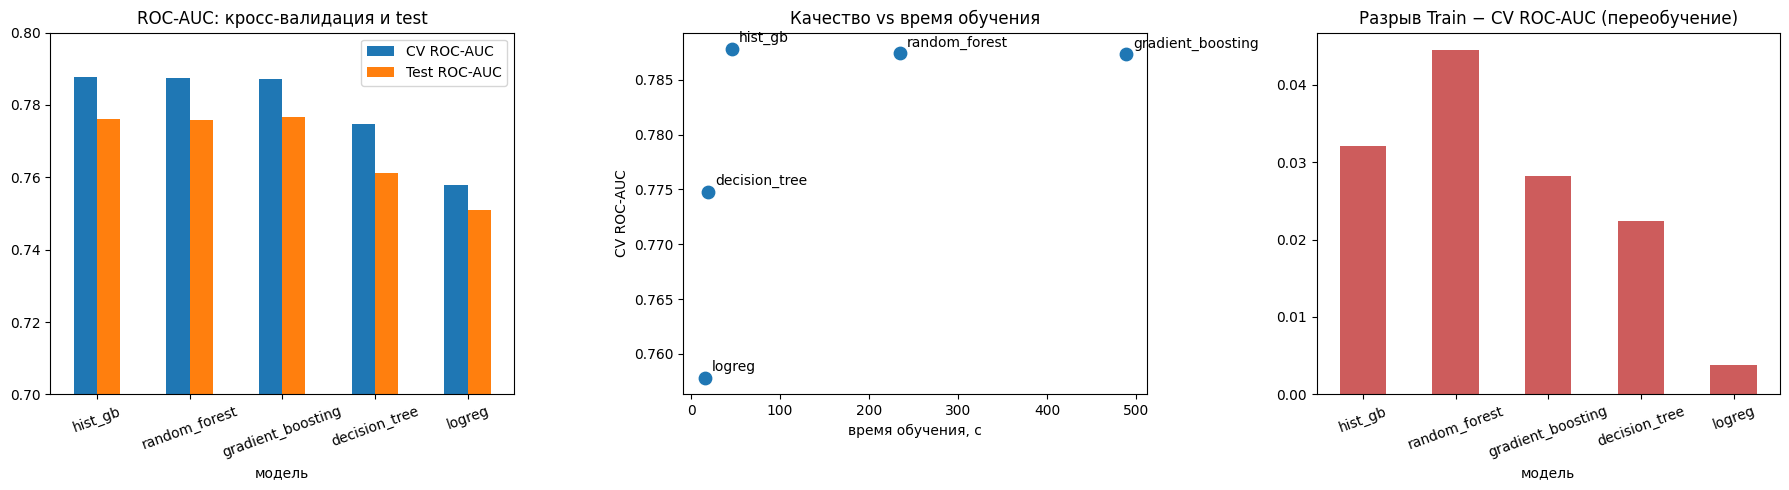

In [ ]:
# Графики сравнения
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
b = board.set_index("модель")

# Качество на CV и на test
b[["CV ROC-AUC", "Test ROC-AUC"]].plot.bar(ax=axes[0], rot=20)
axes[0].set_ylim(0.70, 0.80)
axes[0].set_title("ROC-AUC: кросс-валидация и test")

# Качество против времени, с подписями моделей
axes[1].scatter(b["время, с"], b["CV ROC-AUC"], s=80)
for name, row in b.iterrows():
    axes[1].annotate(name, (row["время, с"], row["CV ROC-AUC"]),
                     textcoords="offset points", xytext=(5, 5))
axes[1].set_xlabel("время обучения, с")
axes[1].set_ylabel("CV ROC-AUC")
axes[1].set_title("Качество vs время обучения")

# Переобучение: разрыв train и CV
(b["Train ROC-AUC"] - b["CV ROC-AUC"]).plot.bar(ax=axes[2], rot=20, color="indianred")
axes[2].set_title("Разрыв Train − CV ROC-AUC (переобучение)")

plt.tight_layout()
fig.savefig("reports/figures/experiments_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

roc_hist_gb.png


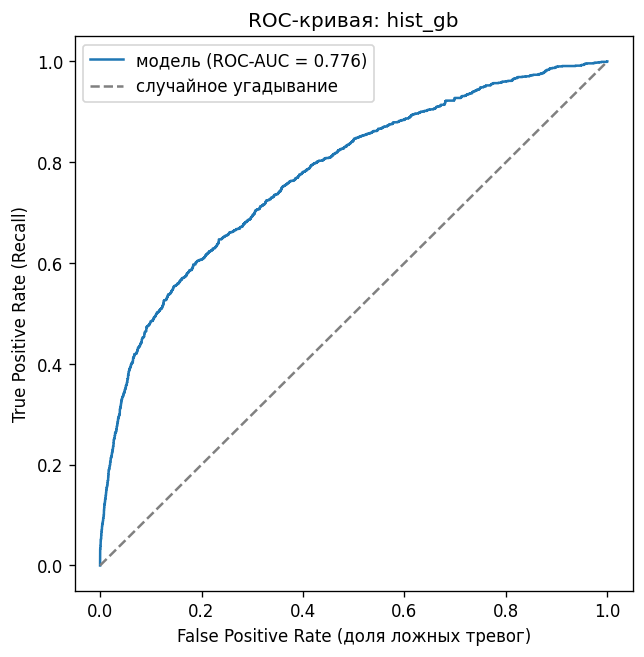

mlflow_runs.png


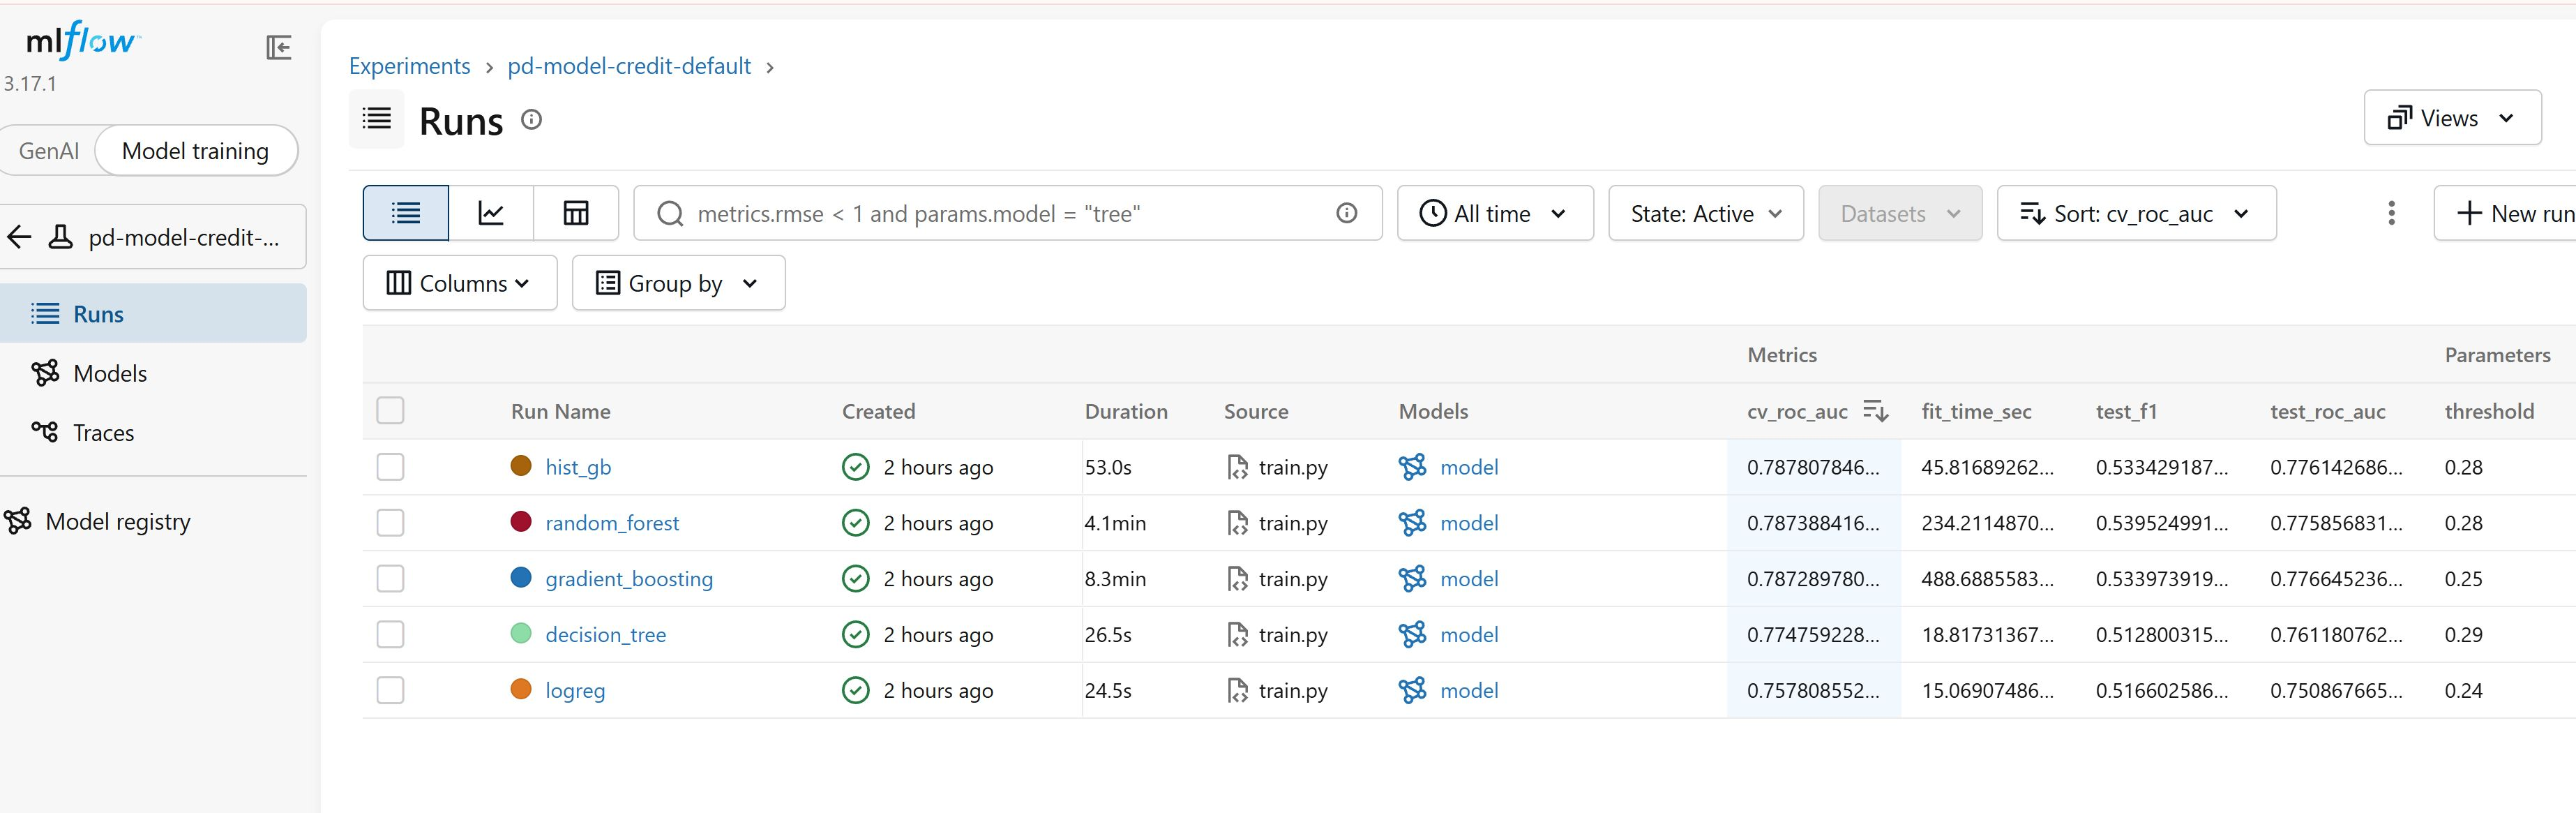

mlflow_compare.png


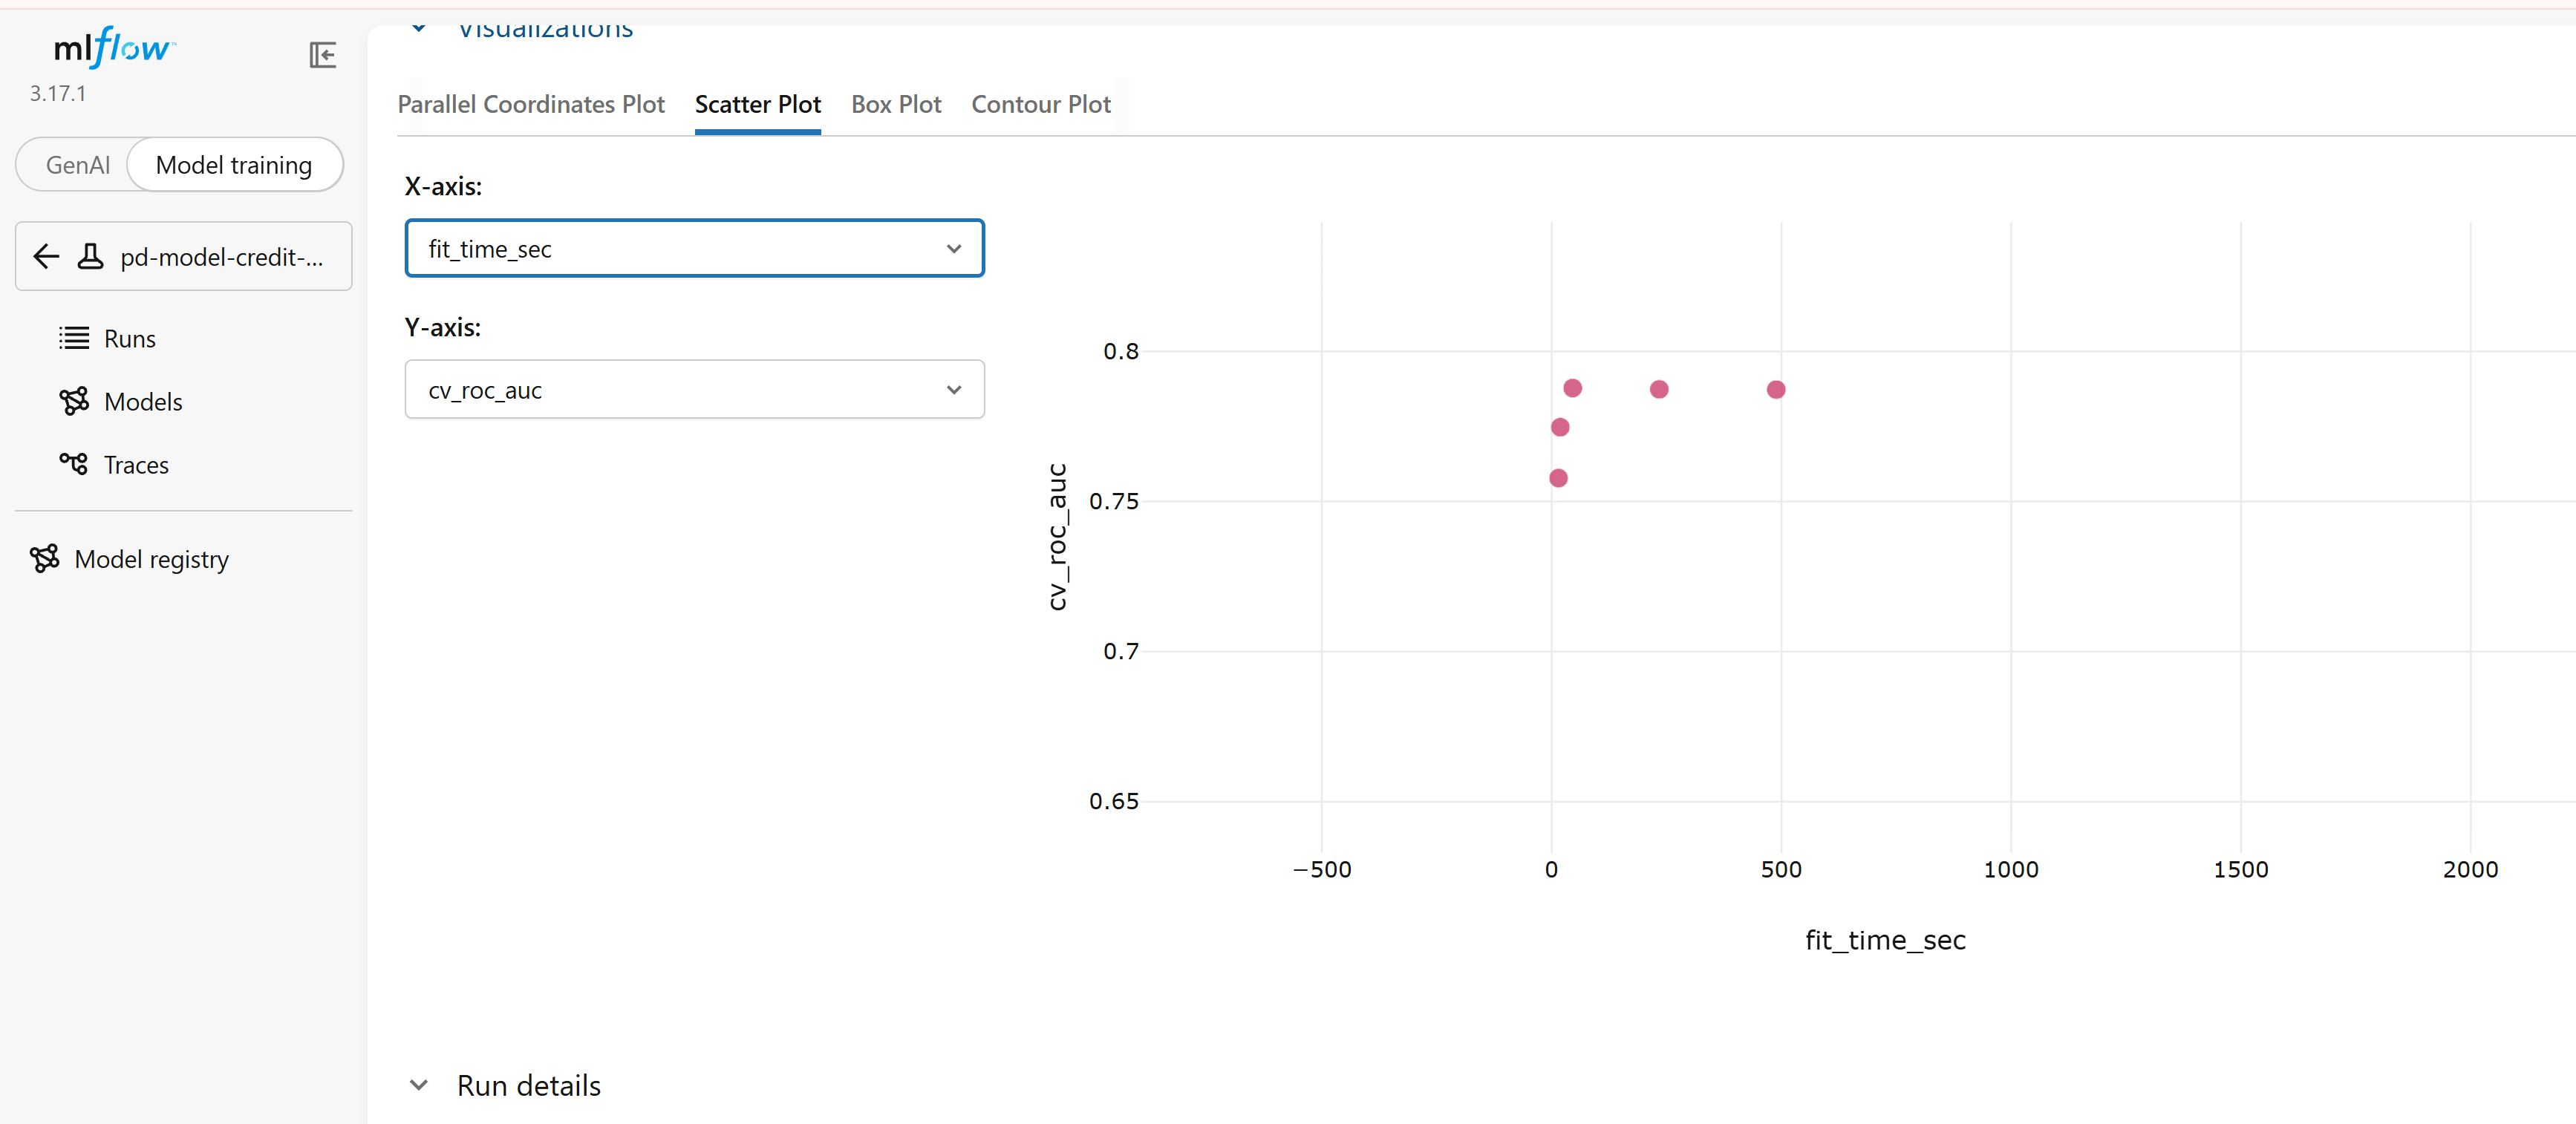

mlflow_run_hist_gb_metrics.png


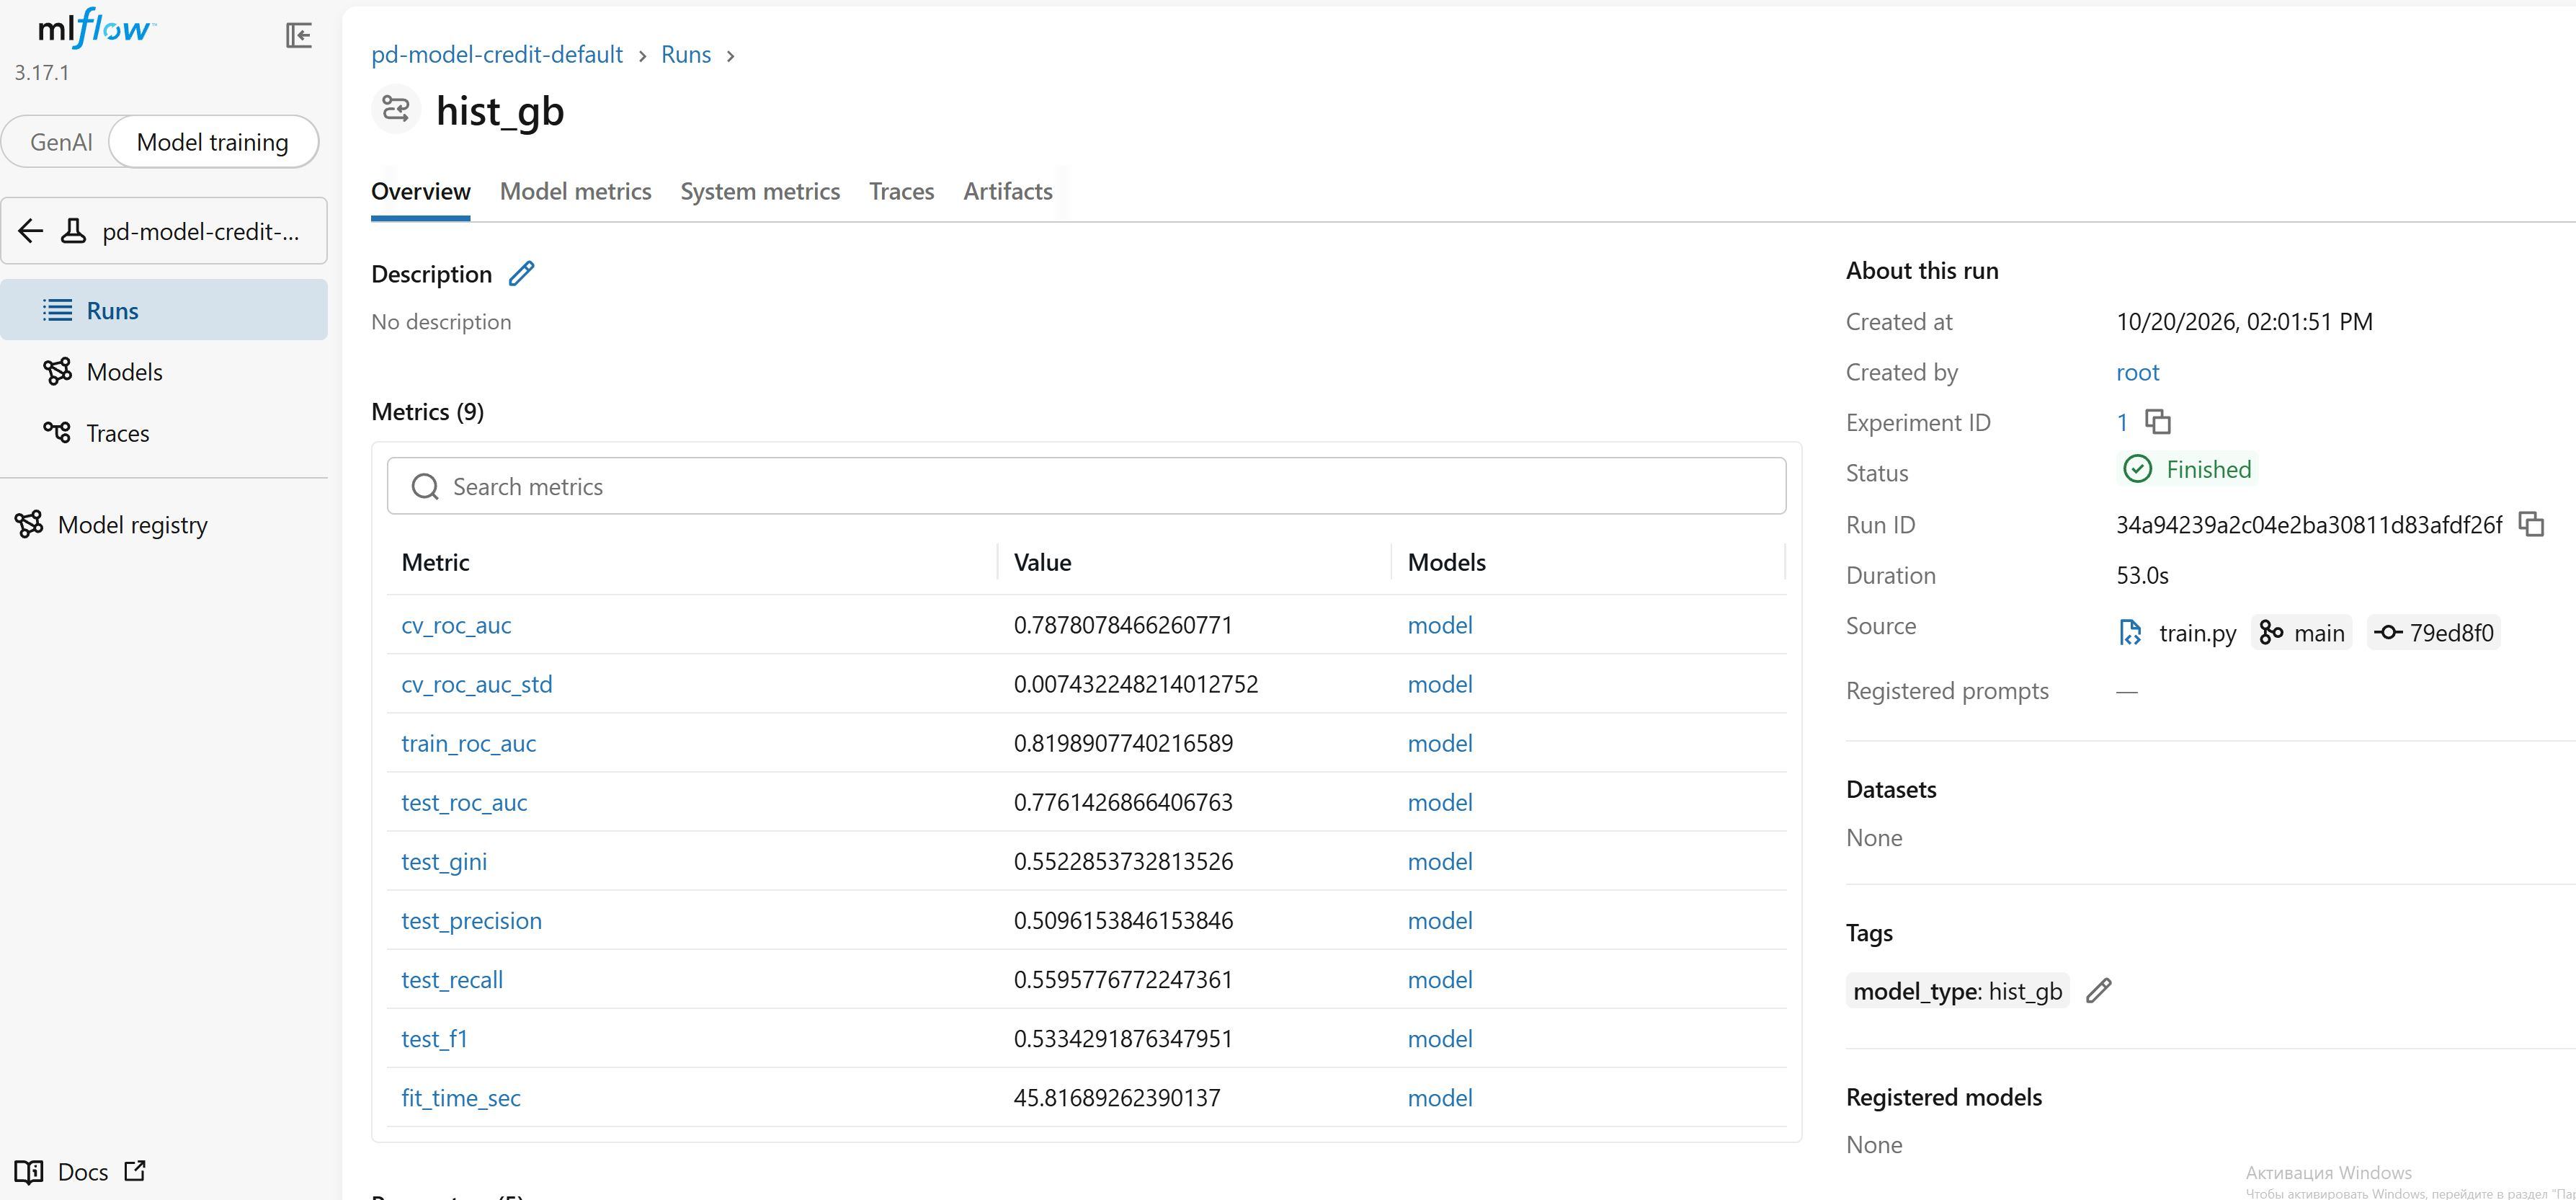

mlflow_run_hist_gb_params.png


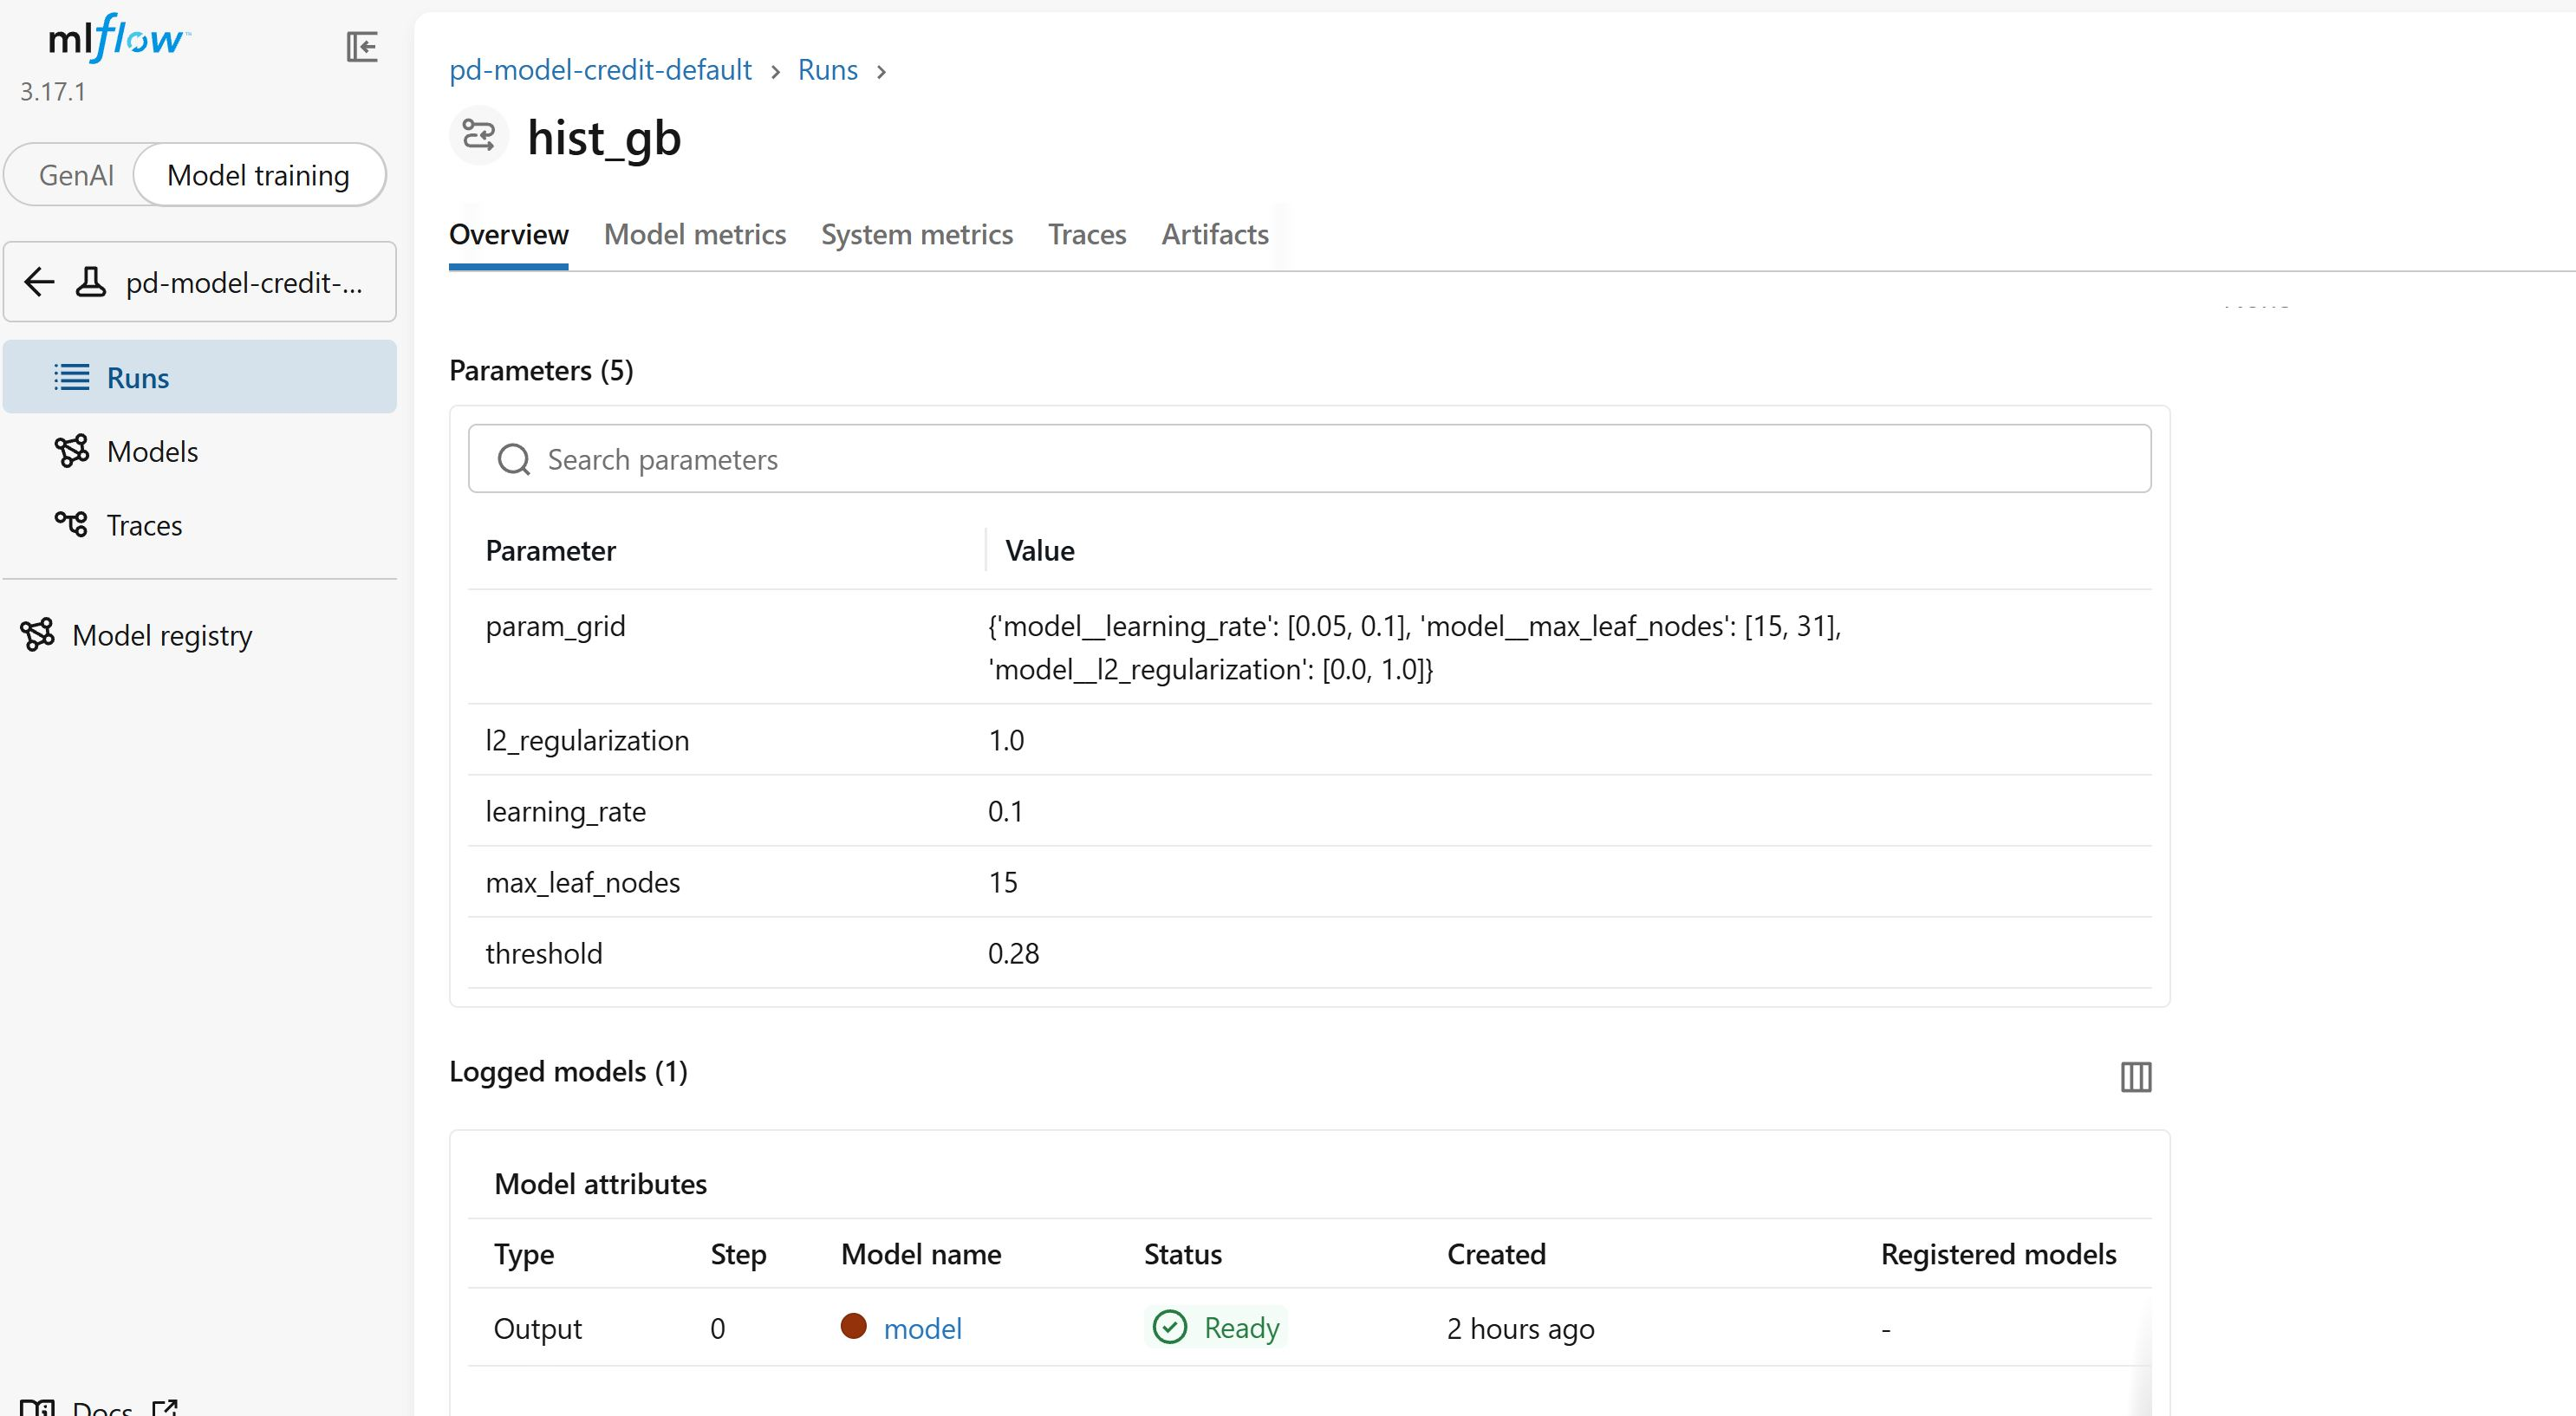

In [ ]:
# ROC лучшей модели и скриншоты MLflow
for f in ["roc_hist_gb.png", "mlflow_runs.png", "mlflow_compare.png",
          "mlflow_run_hist_gb_metrics.png", "mlflow_run_hist_gb_params.png"]:
    print(f)
    display(Image(f"reports/figures/{f}", width=900))

Выводы по экспериментам MLflow (5 моделей, GridSearchCV, 5-fold CV)

| Модель | CV ROC-AUC (± std) | Train ROC-AUC | Test ROC-AUC | Gini | F1 | Время |
|---|---|---|---|---|---|---|
| **HistGradientBoosting** | **0.788** ± 0.007 | 0.820 | 0.776 | 0.552 | 0.533 | **46 с** |
| Случайный лес | 0.787 ± 0.009 | 0.832 | 0.776 | 0.552 | 0.540 | 234 с |
| Градиентный бустинг | 0.787 ± 0.007 | 0.816 | 0.777 | 0.553 | 0.534 | 489 с |
| Дерево решений | 0.775 ± 0.007 | 0.797 | 0.761 | 0.522 | 0.513 | 19 с |
| Логистическая регрессия | 0.758 ± 0.012 | 0.762 | 0.751 | 0.502 | 0.517 | 15 с |

1. Ансамбли деревьев лучше линейной модели на ~0.03 ROC-AUC (≈ +5 п.п. Gini).
   Это подтверждает EDA: зависимости нелинейные (U-форма возраста, J-форма утилизации).
2. Три лучшие модели статистически равны: разница между ними (0.0005) в 15 раз меньше
   разброса между фолдами (std ≈ 0.007–0.009).
3. Выбрана HistGradientBoosting: лучший CV ROC-AUC и в 5–10 раз быстрее леса и бустинга
   (46 с против 234–489 с) — важно для работы в API.
4. Переобучение умеренное и не мешает модели: у ансамблей train ROC-AUC выше CV на 0.03–0.045,
   но test (0.776) близок к CV (0.788), т.е. на новых данных качество сохраняется.
   GridSearchCV выбрал для HistGB регуляризацию (`l2_regularization = 1.0`, `learning_rate = 0.1`) — модель ограничивает сложность.
   Логистическая регрессия почти не переобучается (разрыв 0.004), но слишком простая для этих данных (недообучение).
5. Методика без утечки: лучшая модель и порог выбирались по кросс-валидации на train;
   test использован только для итоговой оценки.
6. Порог классификации подобран по F1 (0.24–0.29 вместо 0.5) из-за дисбаланса классов (22% дефолтов).